# Dvourozměrné spojité rozdělení — marginální a podmíněná rozdělení

**Vstup:** hustota $f(x,y)$ (smí obsahovat jednu neznámou konstantu, např. `c`, která se dopočte z normovací podmínky) a nosič $\Omega$ zadaný nerovnostmi.

**Výstup:** normovací konstanta, meze integrace v obou pořadích, marginální hustoty a distribuční funkce,
$EX, EY, DX, DY, \operatorname{cov}(X,Y), \rho(X,Y)$, rozhodnutí o nezávislosti,
podmíněné hustoty, podmíněné distribuční funkce, podmíněné střední hodnoty a rozptyly a obrázek.

Meze integrace se odvozují automaticky: hranice $\Omega$ se vyřeší vzhledem k $y$ (resp. $x$), průsečíky hranic dají dělicí body
a na každém úseku se rozhodne, která hranice je aktivní dolní a horní mez. Hranice musí jít vyjádřit jako $y=g(x)$ a $x=h(y)$.

Spusťte nejprve buňku s knihovnou, pak upravte zadání a spusťte zbytek (*Run All*).

## Knihovna

In [ ]:
%matplotlib inline
import itertools
import math

import numpy as np
import sympy as sp

x, y = sp.symbols("x y", real=True)
_t = sp.Symbol("t", real=True)


# ----------------------------------------------------------------------------
# 1. Rozklad oblasti na meze integrace
# ----------------------------------------------------------------------------

def _parse_omega(omega):
    """Retezec nebo seznam nerovnosti -> seznam sympy relaci."""
    if isinstance(omega, str):
        parts = [p for p in omega.replace(";", ",").split(",") if p.strip()]
        rels = [sp.sympify(p, locals={"x": x, "y": y}) for p in parts]
    else:
        rels = [sp.sympify(r, locals={"x": x, "y": y}) for r in omega]
    for r in rels:
        if not isinstance(r, sp.core.relational.Relational):
            raise ValueError(f"'{r}' neni nerovnost")
    return rels


def _satisfied(rels_num, xv, yv):
    return all(bool(g(xv, yv)) for g in rels_num)


def _real_value(expr, var, val):
    try:
        v = complex(expr.subs(var, val).evalf())
    except (TypeError, ValueError):
        return None
    if abs(v.imag) > 1e-9 * (1 + abs(v.real)) or not math.isfinite(v.real):
        return None
    return v.real


def _pieces(rels, outer, inner):
    """
    Popise oblast jako sjednoceni useku  a < outer < b,  lo(outer) < inner < up(outer).
    Vraci seznam (a, b, lo, up) se sympy vyrazy (a, b mohou byt -oo/oo).
    """
    rels_num = [sp.lambdify((x, y), r, "math") for r in rels]
    gs = [sp.expand(r.lhs - r.rhs) for r in rels]

    branches = []      # hranice vyjadrene jako inner = b(outer)
    breaks = set()     # delici body pro outer
    for g in gs:
        if g.has(inner):
            sols = [s for s in sp.solve(sp.Eq(g, 0), inner) if s.is_real is not False]
            branches.extend(sols)
            for s1, s2 in itertools.combinations(sols, 2):   # napr. horni a dolni pulkruh
                breaks.update(sp.solve(sp.Eq(s1, s2), outer))
        else:
            breaks.update(sp.solve(sp.Eq(g, 0), outer))
    for b1, b2 in itertools.combinations(branches, 2):         # prusecky hranic
        try:
            breaks.update(sp.solve(sp.Eq(b1, b2), outer))
        except NotImplementedError:
            pass

    bp = sorted({sp.nsimplify(b) for b in breaks if b.is_real}, key=lambda v: float(v))
    edges = [-sp.oo] + bp + [sp.oo]

    pieces = []
    for a, b in zip(edges[:-1], edges[1:]):
        if a == -sp.oo and b == sp.oo:
            m = 0.0
        elif a == -sp.oo:
            m = float(b) - 1.0
        elif b == sp.oo:
            m = float(a) + 1.0
        else:
            m = (float(a) + float(b)) / 2
            if float(b) - float(a) < 1e-12:
                continue
        lows, ups = [], []
        for br in branches:
            v = _real_value(br, outer, m)
            if v is None:
                continue
            eps = 1e-7 * (1 + abs(v))
            pt = (lambda w: (m, w)) if outer == x else (lambda w: (w, m))
            above = _satisfied(rels_num, *pt(v + eps))
            below = _satisfied(rels_num, *pt(v - eps))
            if above and not below:
                lows.append((v, br))
            elif below and not above:
                ups.append((v, br))
        lo = max(lows, key=lambda p: p[0]) if lows else (-math.inf, -sp.oo)
        up = min(ups, key=lambda p: p[0]) if ups else (math.inf, sp.oo)
        if lo[0] >= up[0]:
            continue
        if math.isinf(lo[0]) and math.isinf(up[0]):
            w = 0.0
        elif math.isinf(lo[0]):
            w = up[0] - 1
        elif math.isinf(up[0]):
            w = lo[0] + 1
        else:
            w = (lo[0] + up[0]) / 2
        pt = (m, w) if outer == x else (w, m)
        if not _satisfied(rels_num, *pt):
            continue
        piece = [a, b, sp.simplify(lo[1]), sp.simplify(up[1])]
        if pieces and pieces[-1][1] == a and pieces[-1][2] == piece[2] and pieces[-1][3] == piece[3]:
            pieces[-1][1] = b                       # slouceni navazujicich useku
        else:
            pieces.append(piece)
    if not pieces:
        raise ValueError("Oblast je prazdna nebo ji nelze rozlozit.")
    return [tuple(p) for p in pieces]


# ----------------------------------------------------------------------------
# 2. Symbolicke vypocty
# ----------------------------------------------------------------------------

def _simp(e):
    e = sp.simplify(e)
    try:
        return sp.factor(e) if e.is_rational_function(x, y) else e
    except Exception:
        return e


def _integrate2(expr, pieces, outer, inner):
    return sp.simplify(sum(sp.integrate(sp.integrate(expr, (inner, lo, up)), (outer, a, b))
                           for a, b, lo, up in pieces))


def _mid(a, b):
    if a == -sp.oo and b == sp.oo:
        return 0.0
    if a == -sp.oo:
        return float(b) - 1.0
    if b == sp.oo:
        return float(a) + 1.0
    return (float(a) + float(b)) / 2


def _resolve(expr, subs):
    """Nahradi Piecewise vetvi platnou v reprezentativnim bode `subs` (vnitrek useku)."""
    def pick(pw):
        for e, c in pw.args:
            try:
                if c is sp.true or bool(c.subs(subs)):
                    return e
            except TypeError:
                continue
        return pw
    expr = sp.piecewise_fold(expr)
    for _ in range(5):
        new = expr.replace(lambda e: isinstance(e, sp.Piecewise), pick)
        if new == expr:
            break
        expr = new
    return expr


def _antider(expr, var, a, subs):
    """int_a^var expr d var pres primitivni funkci; `subs` = vnitrni bod pro volbu vetvi."""
    G = _resolve(sp.integrate(expr, var), subs)
    Ga = sp.limit(G, var, a) if a in (-sp.oo, sp.oo) else G.subs(var, a)
    return sp.simplify(_resolve(G - Ga, subs))


def _cdf(dens_pieces, var):
    """dens_pieces: [(a, b, f)] -> Piecewise distribucni funkce."""
    args, acc = [], sp.Integer(0)
    if dens_pieces[0][0] != -sp.oo:
        args.append((sp.Integer(0), var < dens_pieces[0][0]))
    for a, b, fv in dens_pieces:
        F = _simp(acc + _antider(fv, var, a, {var: _mid(a, b)}))
        args.append((F, var < b))
        acc = sp.simplify(acc + sp.integrate(fv, (var, a, b)))
    if dens_pieces[-1][1] != sp.oo:
        args.append((sp.Integer(1), True))
    else:
        args[-1] = (args[-1][0], True)
    return sp.Piecewise(*args)


def _pw(dens_pieces, var):
    """[(a, b, g)] -> Piecewise, mimo nosic 0."""
    args = [(g, (var > a) & (var < b)) for a, b, g in dens_pieces]
    return sp.Piecewise(*args, (0, True))


def _conditional(f, pieces, outer, inner):
    """Podminene rozdeleni inner | outer na kazdem useku."""
    out = []
    for a, b, lo, up in pieces:
        mo = _mid(a, b)
        ptin = {outer: mo, inner: _mid(lo.subs(outer, mo), up.subs(outer, mo))}
        integ = lambda g: _resolve(sp.integrate(g, (inner, lo, up)), {outer: mo})
        marg = _simp(integ(f))
        dens = _simp(f / marg)
        cdf = _simp(_antider(f, inner, lo, ptin) / marg)
        m1 = _simp(integ(inner * f) / marg)
        m2 = integ(inner ** 2 * f) / marg
        var = _simp(m2 - m1 ** 2)
        out.append(dict(a=a, b=b, lo=lo, up=up, marg=marg, dens=dens, cdf=cdf, mean=m1, var=var))
    return out


def analyzuj(hustota, omega, tisk=True, latex=False, obrazek=True, out=None, rovnake_osy=True):
    f = sp.sympify(hustota, locals={"x": x, "y": y})
    rels = _parse_omega(omega)

    px = _pieces(rels, x, y)       # a < x < b,  lo(x) < y < up(x)
    py = _pieces(rels, y, x)       # a < y < b,  lo(y) < x < up(y)

    # normovaci konstanta
    params = sorted(f.free_symbols - {x, y}, key=str)
    const = None
    if len(params) > 1:
        raise ValueError(f"Hustota obsahuje vice neznamych: {params}")
    if params:
        total = _integrate2(f, px, x, y)
        sol = sp.solve(sp.Eq(total, 1), params[0])
        if not sol:
            raise ValueError("Nepodarilo se urcit normovaci konstantu.")
        const = (params[0], sp.nsimplify(sol[0]))
        f = f.subs(*const)
    total = _integrate2(f, px, x, y)
    if sp.simplify(total - 1) != 0:
        print(f"POZOR: integral hustoty pres Omega = {total}, ne 1.")

    # kontrola nezapornosti na mrizce
    # (provadi se pozdeji spolu s obrazkem, zde jen symbolika)

    condY = _conditional(f, px, x, y)    # Y | X = x
    condX = _conditional(f, py, y, x)    # X | Y = y

    fX = _pw([(c["a"], c["b"], c["marg"]) for c in condY], x)
    fY = _pw([(c["a"], c["b"], c["marg"]) for c in condX], y)
    FX = _cdf([(c["a"], c["b"], c["marg"]) for c in condY], x)
    FY = _cdf([(c["a"], c["b"], c["marg"]) for c in condX], y)

    EX = _integrate2(x * f, px, x, y)
    EY = _integrate2(y * f, px, x, y)
    DX = sp.simplify(_integrate2(x ** 2 * f, px, x, y) - EX ** 2)
    DY = sp.simplify(_integrate2(y ** 2 * f, px, x, y) - EY ** 2)
    EXY = _integrate2(x * y * f, px, x, y)
    cov = sp.simplify(EXY - EX * EY)
    rho = sp.simplify(cov / sp.sqrt(DX * DY))

    # nezavislost: f = f_X f_Y na nosici a nosic je obdelnik
    indep = len(px) == 1 and not px[0][2].has(x) and not px[0][3].has(x) and \
        sp.simplify(f - condY[0]["marg"] * condX[0]["marg"]) == 0

    R = dict(f=f, konstanta=const, omega_x=px, omega_y=py,
             fX=fX, fY=fY, FX=FX, FY=FY, EX=EX, EY=EY, DX=DX, DY=DY,
             cov=cov, rho=rho, nezavisle=indep, podm_Y_pri_X=condY, podm_X_pri_Y=condX,
             omega_rel=rels)

    if tisk:
        _report(R, latex)
    if obrazek:
        _plot(R, rels, out, rovnake_osy)
    return R


# ----------------------------------------------------------------------------
# 3. Tisk
# ----------------------------------------------------------------------------

def _report(R, latex):
    show = (lambda e: sp.latex(e)) if latex else (lambda e: sp.pretty(e, use_unicode=True))
    num = lambda e: f"{float(e):.6g}"

    def head(s):
        print("\n" + s + "\n" + "-" * len(s))

    def block(label, e):
        s = show(e)
        if "\n" in s:
            print(label + ":")
            print("   " + s.replace("\n", "\n   "))
        else:
            print(f"{label} = {s}")

    head("Hustota")
    if R["konstanta"]:
        print(f"normovaci konstanta {R['konstanta'][0]} = {sp.latex(R['konstanta'][1]) if latex else sp.sstr(R['konstanta'][1])}")
    block("f(x, y)", R["f"])

    head("Omega (poradi dy dx)")
    for a, b, lo, up in R["omega_x"]:
        print(f"   {a} < x < {b},   {lo} < y < {up}")
    head("Omega (poradi dx dy)")
    for a, b, lo, up in R["omega_y"]:
        print(f"   {a} < y < {b},   {lo} < x < {up}")

    head("Marginalni rozdeleni")
    block("f_X(x)", R["fX"])
    block("F_X(x)", R["FX"])
    block("f_Y(y)", R["fY"])
    block("F_Y(y)", R["FY"])

    head("Momenty")
    inline = (lambda e: sp.latex(e)) if latex else sp.sstr
    for k in ("EX", "EY", "DX", "DY", "cov", "rho"):
        print(f"{k:>4} = {inline(R[k]):<30}  ~ {num(R[k])}")
    print("\nX a Y jsou", "NEZAVISLE" if R["nezavisle"] else "ZAVISLE")

    for key, (co, pri) in (("podm_Y_pri_X", ("y", "x")), ("podm_X_pri_Y", ("x", "y"))):
        head(f"Podminene rozdeleni {co.upper()} | {pri.upper()} = {pri}")
        for c in R[key]:
            print(f"\n pro {c['a']} < {pri} < {c['b']},   nosic {c['lo']} < {co} < {c['up']}:")
            block(f"   f({co}|{pri})", c["dens"])
            block(f"   F({co}|{pri})", c["cdf"])
            block(f"   E({co.upper()}|{pri.upper()}={pri})", c["mean"])
            block(f"   D({co.upper()}|{pri.upper()}={pri})", c["var"])


# ----------------------------------------------------------------------------
# 4. Obrazek
# ----------------------------------------------------------------------------

def _num(e, var):
    fn = sp.lambdify(var, e, "numpy")

    def g(v):
        with np.errstate(all="ignore"):
            return np.broadcast_to(np.real(np.asarray(fn(v))).astype(float), np.shape(v)).copy()
    return g


def _range(pieces_cond, Fnum):
    a = float(pieces_cond[0]["a"])
    b = float(pieces_cond[-1]["b"])
    if math.isinf(a) or math.isinf(b):         # neomezeny nosic -> kvantily 0,2 % a 99,8 %
        lo_s = -1e3 if math.isinf(a) else a
        hi_s = 1e3 if math.isinf(b) else b
        grid = np.linspace(lo_s, hi_s, 200001)
        Fg = Fnum(grid)
        if math.isinf(a):
            a = grid[np.searchsorted(Fg, 0.002)]
        if math.isinf(b):
            b = grid[min(np.searchsorted(Fg, 0.998), len(grid) - 1)]
    return a, b


def kresli(R, out=None, rovnake_osy=True):
    """Obrazek k vysledku funkce analyzuj."""
    _plot(R, R["omega_rel"], out, rovnake_osy)


def _plot(R, rels, out, equal):
    import matplotlib.pyplot as plt

    f, cY, cX = R["f"], R["podm_Y_pri_X"], R["podm_X_pri_Y"]
    fXn, fYn = _num(R["fX"], x), _num(R["fY"], y)
    FXn, FYn = _num(R["FX"], x), _num(R["FY"], y)
    xa, xb = _range(cY, FXn)
    ya, yb = _range(cX, FYn)
    padx, pady = 0.06 * (xb - xa), 0.06 * (yb - ya)

    # hustota na mrizce
    fn = sp.lambdify((x, y), f, "numpy")
    ind = [sp.lambdify((x, y), r, "numpy") for r in rels]
    gx = np.linspace(xa - padx, xb + padx, 500)
    gy = np.linspace(ya - pady, yb + pady, 500)
    GX, GY = np.meshgrid(gx, gy)
    mask = np.ones_like(GX, dtype=bool)
    for g in ind:
        mask &= np.asarray(g(GX, GY), dtype=bool)
    with np.errstate(all="ignore"):
        Z = np.broadcast_to(np.asarray(fn(GX, GY), dtype=float), GX.shape).copy()
    Z[~mask] = np.nan
    if np.nanmin(Z) < -1e-12:
        print(f"POZOR: hustota je na Omega misty zaporna (min = {np.nanmin(Z):.4g}).")

    fig = plt.figure(figsize=(16, 8.5), constrained_layout=True)
    gsp = fig.add_gridspec(2, 4)
    col_y, col_x = "#d95926", "#199e70"

    def support(ax):
        im = ax.pcolormesh(GX, GY, Z, cmap="Blues", shading="auto", alpha=0.85)
        ax.contour(GX, GY, mask.astype(float), levels=[0.5], colors="k", linewidths=1)
        ax.set_xlim(gx[0], gx[-1]); ax.set_ylim(gy[0], gy[-1])
        ax.set_xlabel("x"); ax.set_ylabel("y")
        if equal:
            ax.set_aspect("equal")
        return im

    def band(ax, cond, var, color, swap):
        for c in cond:
            a = max(float(c["a"]), (xa if not swap else ya))
            b = min(float(c["b"]), (xb if not swap else yb))
            t = np.linspace(a, b, 400)[1:-1]
            m = _num(c["mean"], var)(t)
            s = np.sqrt(np.clip(_num(c["var"], var)(t), 0, None))
            if swap:
                ax.fill_betweenx(t, m - s, m + s, color=color, alpha=0.25, lw=0)
                ax.plot(m, t, color=color, lw=2.2)
                ax.plot(m - s, t, m + s, t, color=color, lw=0.8, ls="--")
            else:
                ax.fill_between(t, m - s, m + s, color=color, alpha=0.25, lw=0)
                ax.plot(t, m, color=color, lw=2.2)
                ax.plot(t, m - s, t, m + s, color=color, lw=0.8, ls="--")

    mx, my = float(R["EX"]), float(R["EY"])

    ax = fig.add_subplot(gsp[:, 0])
    im = support(ax)
    band(ax, cY, x, col_y, swap=False)
    ax.plot(mx, my, "o", color="#2a78d6", mec="white", ms=8)
    ax.set_title("E(Y | X=x) ± σ(Y | X=x)")
    fig.colorbar(im, ax=ax, shrink=0.6, label="f(x, y)")

    ax = fig.add_subplot(gsp[:, 1])
    support(ax)
    band(ax, cX, y, col_x, swap=True)
    ax.plot(mx, my, "o", color="#2a78d6", mec="white", ms=8)
    ax.set_title("E(X | Y=y) ± σ(X | Y=y)")

    def cond_dens(ax, cond, var, other, Fn, a, b, label):
        qs = [0.25, 0.5, 0.75]
        grid = np.linspace(a, b, 20001)
        Fg = Fn(grid)
        for q, ls in zip(qs, ["-", "--", ":"]):
            v0 = grid[min(np.searchsorted(Fg, q), len(grid) - 1)]
            c = next((c for c in cond if float(c["a"]) <= v0 <= float(c["b"])), None)
            if c is None:
                continue
            lo = float(c["lo"].subs(var, v0)) if c["lo"] != -sp.oo else None
            up = float(c["up"].subs(var, v0)) if c["up"] != sp.oo else None
            lo = lo if lo is not None else (ya if other == y else xa)
            up = up if up is not None else (yb if other == y else xb)
            t = np.linspace(lo, up, 400)
            dens = sp.lambdify(other, c["dens"].subs(var, v0), "numpy")
            with np.errstate(all="ignore"):
                vals = np.broadcast_to(np.asarray(dens(t), dtype=float), t.shape)
            ax.plot(t, vals, ls=ls, color="k", lw=1.6, label=f"{label} = {v0:.3g}")
        ax.set_ylim(bottom=0)
        ax.legend(fontsize=9)

    ax = fig.add_subplot(gsp[0, 2])
    cond_dens(ax, cY, x, y, FXn, xa, xb, "x")
    ax.set_title("f(y | x) pro kvartily X"); ax.set_xlabel("y")

    ax = fig.add_subplot(gsp[0, 3])
    cond_dens(ax, cX, y, x, FYn, ya, yb, "y")
    ax.set_title("f(x | y) pro kvartily Y"); ax.set_xlabel("x")

    ax = fig.add_subplot(gsp[1, 2])
    tx = np.linspace(xa - padx, xb + padx, 800)
    ax.plot(tx, fXn(tx), color="#2a78d6", lw=2, label="f_X")
    ax.plot(tx, FXn(tx), color="#888780", lw=1.5, ls="--", label="F_X")
    ax.axvline(mx, color="#2a78d6", lw=0.8, ls=":")
    ax.set_title(f"X:  EX = {mx:.4g},  DX = {float(R['DX']):.4g}"); ax.set_xlabel("x")
    ax.legend(fontsize=9); ax.set_ylim(bottom=0)

    ax = fig.add_subplot(gsp[1, 3])
    ty = np.linspace(ya - pady, yb + pady, 800)
    ax.plot(ty, fYn(ty), color="#2a78d6", lw=2, label="f_Y")
    ax.plot(ty, FYn(ty), color="#888780", lw=1.5, ls="--", label="F_Y")
    ax.axvline(my, color="#2a78d6", lw=0.8, ls=":")
    ax.set_title(f"Y:  EY = {my:.4g},  DY = {float(R['DY']):.4g}"); ax.set_xlabel("y")
    ax.legend(fontsize=9); ax.set_ylim(bottom=0)

    fig.suptitle(f"f(x, y) = {R['f']}      cov = {float(R['cov']):.4g},  ρ = {float(R['rho']):.4g}")
    if out:
        fig.savefig(out, dpi=150)
        print(f"\nObrazek ulozen do {out}")
    else:
        plt.show()


# ----------------------------------------------------------------------------


from IPython.display import display, Markdown

def zobraz(R):
    """Vysledky funkce analyzuj vysazene v LaTeXu."""
    L = lambda e: (sp.latex(e).replace(r"\text{for}\:", r"\text{pro}\ ")
                   .replace(r"\text{otherwise}", r"\text{jinak}").replace(r"\wedge", r"\ \wedge\ "))
    md = []
    if R["konstanta"]:
        md.append(f"**Normovací konstanta:** ${L(R['konstanta'][0])} = {L(R['konstanta'][1])}$")
    md.append(f"$$f(x,y) = {L(R['f'])}$$")
    md.append("**Ω v pořadí dy dx:** " + ";  ".join(
        f"${L(a)} < x < {L(b)},\\ {L(lo)} < y < {L(up)}$" for a, b, lo, up in R["omega_x"]))
    md.append("**Ω v pořadí dx dy:** " + ";  ".join(
        f"${L(a)} < y < {L(b)},\\ {L(lo)} < x < {L(up)}$" for a, b, lo, up in R["omega_y"]))
    md.append("### Marginální rozdělení")
    for k, n in (("fX", "f_X(x)"), ("FX", "F_X(x)"), ("fY", "f_Y(y)"), ("FY", "F_Y(y)")):
        md.append(f"$$ {n} = {L(R[k])} $$")
    md.append("### Momenty")
    rows = "\n".join(f"| ${n}$ | ${L(R[k])}$ | {float(R[k]):.6g} |" for k, n in
                     (("EX", "EX"), ("EY", "EY"), ("DX", "DX"), ("DY", "DY"),
                      ("cov", r"\operatorname{cov}(X,Y)"), ("rho", r"\rho(X,Y)")))
    md.append("| | přesně | přibližně |\n|---|---|---|\n" + rows)
    md.append(f"**X a Y jsou {'nezávislé' if R['nezavisle'] else 'závislé'}.**")
    for key, co, pri in (("podm_Y_pri_X", "y", "x"), ("podm_X_pri_Y", "x", "y")):
        md.append(f"### Podmíněné rozdělení ${co.upper()} \\mid {pri.upper()} = {pri}$")
        for c in R[key]:
            md.append(f"Pro ${L(c['a'])} < {pri} < {L(c['b'])}$, nosič ${L(c['lo'])} < {co} < {L(c['up'])}$:")
            md.append(
                f"$$ f({co}\\mid {pri}) = {L(c['dens'])}, \\qquad F({co}\\mid {pri}) = {L(c['cdf'])} $$\n"
                f"$$ E({co.upper()}\\mid {pri.upper()}={pri}) = {L(c['mean'])}, \\qquad "
                f"D({co.upper()}\\mid {pri.upper()}={pri}) = {L(c['var'])} $$")
    display(Markdown("\n\n".join(md)))


## Zadání

In [ ]:
hustota = "c*(3*x + 2*y + x*y)"
omega   = "x > 0, y > 0, x + y/2 < 1"

## Výpočet

In [ ]:
R = analyzuj(hustota, omega, tisk=False, obrazek=False)
zobraz(R)

**Normovací konstanta:** $c = \frac{2}{5}$

$$f(x,y) = \frac{2 x y}{5} + \frac{6 x}{5} + \frac{4 y}{5}$$

**Ω v pořadí dy dx:** $0 < x < 1,\ 0 < y < 2 - 2 x$

**Ω v pořadí dx dy:** $0 < y < 2,\ 0 < x < 1 - \frac{y}{2}$

### Marginální rozdělení

$$ f_X(x) = \begin{cases} \frac{4 \left(x - 1\right) \left(x^{2} - 2 x - 2\right)}{5} & \text{pro}\  x > 0 \ \wedge\  x < 1 \\0 & \text{jinak} \end{cases} $$

$$ F_X(x) = \begin{cases} 0 & \text{pro}\  x < 0 \\\frac{x \left(x - 2\right) \left(x^{2} - 2 x - 4\right)}{5} & \text{pro}\  x < 1 \\1 & \text{jinak} \end{cases} $$

$$ f_Y(y) = \begin{cases} \frac{\left(y - 2\right) \left(y^{2} - 7 y - 6\right)}{20} & \text{pro}\  y > 0 \ \wedge\  y < 2 \\0 & \text{jinak} \end{cases} $$

$$ F_Y(y) = \begin{cases} 0 & \text{pro}\  y < 0 \\\frac{y \left(y^{3} - 12 y^{2} + 16 y + 48\right)}{80} & \text{pro}\  y < 2 \\1 & \text{jinak} \end{cases} $$

### Momenty

| | přesně | přibližně |
|---|---|---|
| $EX$ | $\frac{9}{25}$ | 0.36 |
| $EY$ | $\frac{59}{75}$ | 0.786667 |
| $DX$ | $\frac{107}{1875}$ | 0.0570667 |
| $DY$ | $\frac{1319}{5625}$ | 0.234489 |
| $\operatorname{cov}(X,Y)$ | $- \frac{443}{5625}$ | -0.0787556 |
| $\rho(X,Y)$ | $- \frac{443 \sqrt{423399}}{423399}$ | -0.680815 |

**X a Y jsou závislé.**

### Podmíněné rozdělení $Y \mid X = x$

Pro $0 < x < 1$, nosič $0 < y < 2 - 2 x$:

$$ f(y\mid x) = \frac{x y + 3 x + 2 y}{2 \left(x - 1\right) \left(x^{2} - 2 x - 2\right)}, \qquad F(y\mid x) = \frac{y \left(x y + 6 x + 2 y\right)}{4 \left(x - 1\right) \left(x^{2} - 2 x - 2\right)} $$
$$ E(Y\mid X=x) = - \frac{\left(x - 1\right) \left(4 x^{2} - 5 x - 8\right)}{3 \left(x^{2} - 2 x - 2\right)}, \qquad D(Y\mid X=x) = \frac{\left(x - 1\right)^{2} \left(2 x^{4} - 14 x^{3} + 3 x^{2} + 28 x + 8\right)}{9 \left(x^{2} - 2 x - 2\right)^{2}} $$

### Podmíněné rozdělení $X \mid Y = y$

Pro $0 < y < 2$, nosič $0 < x < 1 - \frac{y}{2}$:

$$ f(x\mid y) = \frac{8 \left(x y + 3 x + 2 y\right)}{\left(y - 2\right) \left(y^{2} - 7 y - 6\right)}, \qquad F(x\mid y) = \frac{4 x \left(x y + 3 x + 4 y\right)}{\left(y - 2\right) \left(y^{2} - 7 y - 6\right)} $$
$$ E(X\mid Y=y) = - \frac{\left(y - 6\right) \left(y - 2\right) \left(y + 1\right)}{3 \left(y^{2} - 7 y - 6\right)}, \qquad D(X\mid Y=y) = \frac{\left(y - 2\right)^{2} \left(y^{4} - 22 y^{3} + 61 y^{2} + 132 y + 36\right)}{72 \left(y^{2} - 7 y - 6\right)^{2}} $$

## Obrázek

Nosič s hustotou a pásy $E \pm \sigma$ podmíněných rozdělení (stejné měřítko os), podmíněné hustoty v kvartilech, marginální hustoty a distribuční funkce. Uložení: `kresli(R, out="obr.pdf")`.

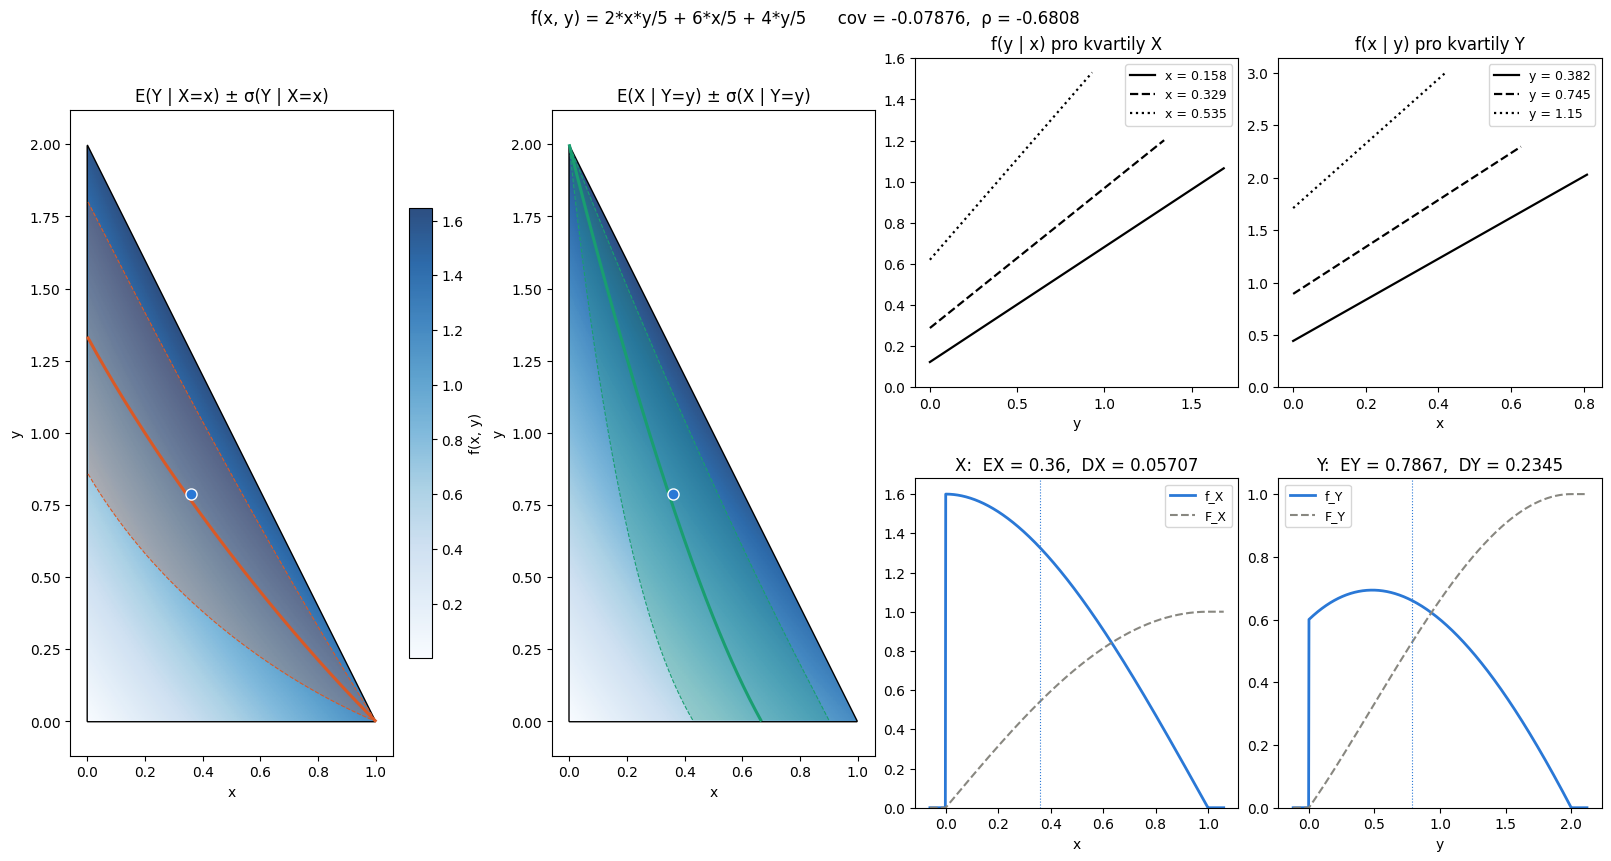

In [ ]:
kresli(R)

## Výstup pro skripta (LaTeX)

Stejné výsledky jako text v LaTeXu ke zkopírování.

In [ ]:
_report(R, latex=True)


Hustota
-------
normovaci konstanta c = \frac{2}{5}
f(x, y) = \frac{2 x y}{5} + \frac{6 x}{5} + \frac{4 y}{5}

Omega (poradi dy dx)
--------------------
   0 < x < 1,   0 < y < 2 - 2*x

Omega (poradi dx dy)
--------------------
   0 < y < 2,   0 < x < 1 - y/2

Marginalni rozdeleni
--------------------
f_X(x) = \begin{cases} \frac{4 \left(x - 1\right) \left(x^{2} - 2 x - 2\right)}{5} & \text{for}\: x > 0 \wedge x < 1 \\0 & \text{otherwise} \end{cases}
F_X(x) = \begin{cases} 0 & \text{for}\: x < 0 \\\frac{x \left(x - 2\right) \left(x^{2} - 2 x - 4\right)}{5} & \text{for}\: x < 1 \\1 & \text{otherwise} \end{cases}
f_Y(y) = \begin{cases} \frac{\left(y - 2\right) \left(y^{2} - 7 y - 6\right)}{20} & \text{for}\: y > 0 \wedge y < 2 \\0 & \text{otherwise} \end{cases}
F_Y(y) = \begin{cases} 0 & \text{for}\: y < 0 \\\frac{y \left(y^{3} - 12 y^{2} + 16 y + 48\right)}{80} & \text{for}\: y < 2 \\1 & \text{otherwise} \end{cases}

Momenty
-------
  EX = \frac{9}{25}                    ~ 0.36
  EY = 

## Další příklady

Stačí přepsat zadání výše, nebo spustit některý z řádků:

| hustota | Ω | poznámka |
|---|---|---|
| `"c"` | `"x>0, x<1, y>0, y<3"` | rovnoměrné rozdělení na obdélníku, nezávislé |
| `"c*x*y"` | `"y>0, y<x, y<2-x"` | lomená mez, $X$ má dva úseky |
| `"c"` | `"x**2+y**2<1"` | kruh: $\operatorname{cov}=0$, ale závislé |
| `"c*exp(-x-2*y)"` | `"x>0, y>0"` | neomezený nosič, nezávislé |
| `"c*(x+y)"` | `"x>0, y>0, y<1-x**2"` | oblast pod parabolou |

**Normovací konstanta:** $c = \frac{1}{\pi}$

$$f(x,y) = \frac{1}{\pi}$$

**Ω v pořadí dy dx:** $-1 < x < 1,\ - \sqrt{1 - x^{2}} < y < \sqrt{1 - x^{2}}$

**Ω v pořadí dx dy:** $-1 < y < 1,\ - \sqrt{1 - y^{2}} < x < \sqrt{1 - y^{2}}$

### Marginální rozdělení

$$ f_X(x) = \begin{cases} \frac{2 \sqrt{1 - x^{2}}}{\pi} & \text{pro}\  x > -1 \ \wedge\  x < 1 \\0 & \text{jinak} \end{cases} $$

$$ F_X(x) = \begin{cases} 0 & \text{pro}\  x < -1 \\\frac{x \sqrt{1 - x^{2}} + \operatorname{asin}{\left(x \right)} + \frac{\pi}{2}}{\pi} & \text{pro}\  x < 1 \\1 & \text{jinak} \end{cases} $$

$$ f_Y(y) = \begin{cases} \frac{2 \sqrt{1 - y^{2}}}{\pi} & \text{pro}\  y > -1 \ \wedge\  y < 1 \\0 & \text{jinak} \end{cases} $$

$$ F_Y(y) = \begin{cases} 0 & \text{pro}\  y < -1 \\\frac{y \sqrt{1 - y^{2}} + \operatorname{asin}{\left(y \right)} + \frac{\pi}{2}}{\pi} & \text{pro}\  y < 1 \\1 & \text{jinak} \end{cases} $$

### Momenty

| | přesně | přibližně |
|---|---|---|
| $EX$ | $0$ | 0 |
| $EY$ | $0$ | 0 |
| $DX$ | $\frac{1}{4}$ | 0.25 |
| $DY$ | $\frac{1}{4}$ | 0.25 |
| $\operatorname{cov}(X,Y)$ | $0$ | 0 |
| $\rho(X,Y)$ | $0$ | 0 |

**X a Y jsou závislé.**

### Podmíněné rozdělení $Y \mid X = x$

Pro $-1 < x < 1$, nosič $- \sqrt{1 - x^{2}} < y < \sqrt{1 - x^{2}}$:

$$ f(y\mid x) = \frac{1}{2 \sqrt{1 - x^{2}}}, \qquad F(y\mid x) = \frac{y}{2 \sqrt{1 - x^{2}}} + \frac{1}{2} $$
$$ E(Y\mid X=x) = 0, \qquad D(Y\mid X=x) = - \frac{\left(x - 1\right) \left(x + 1\right)}{3} $$

### Podmíněné rozdělení $X \mid Y = y$

Pro $-1 < y < 1$, nosič $- \sqrt{1 - y^{2}} < x < \sqrt{1 - y^{2}}$:

$$ f(x\mid y) = \frac{1}{2 \sqrt{1 - y^{2}}}, \qquad F(x\mid y) = \frac{x}{2 \sqrt{1 - y^{2}}} + \frac{1}{2} $$
$$ E(X\mid Y=y) = 0, \qquad D(X\mid Y=y) = - \frac{\left(y - 1\right) \left(y + 1\right)}{3} $$

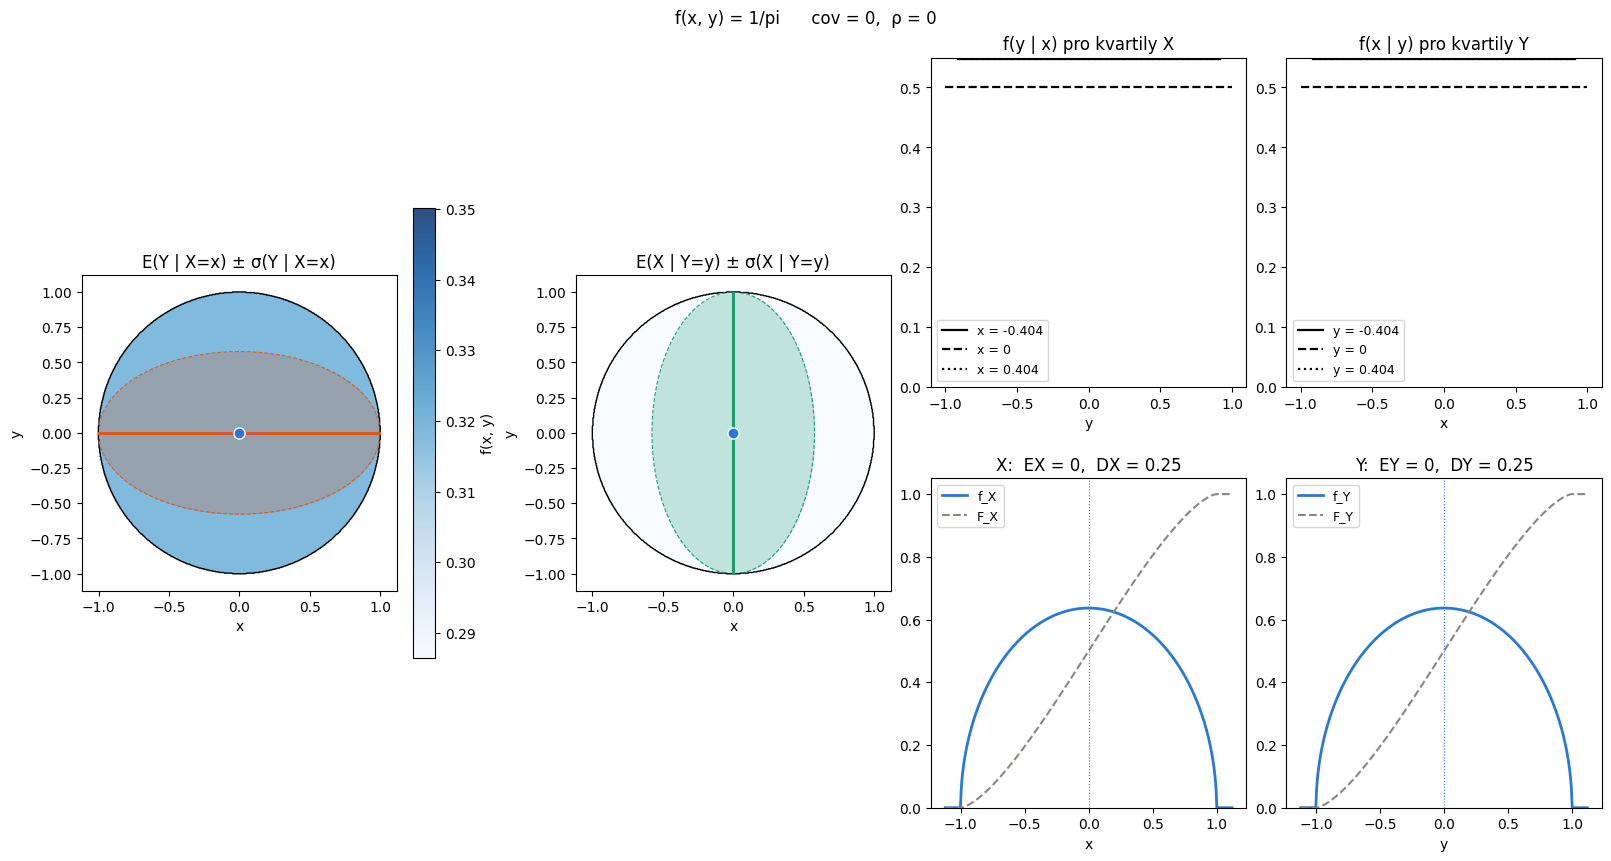

In [ ]:
R2 = analyzuj("c", "x**2 + y**2 < 1", tisk=False, obrazek=False)
zobraz(R2)
kresli(R2)